Graph generation and display:


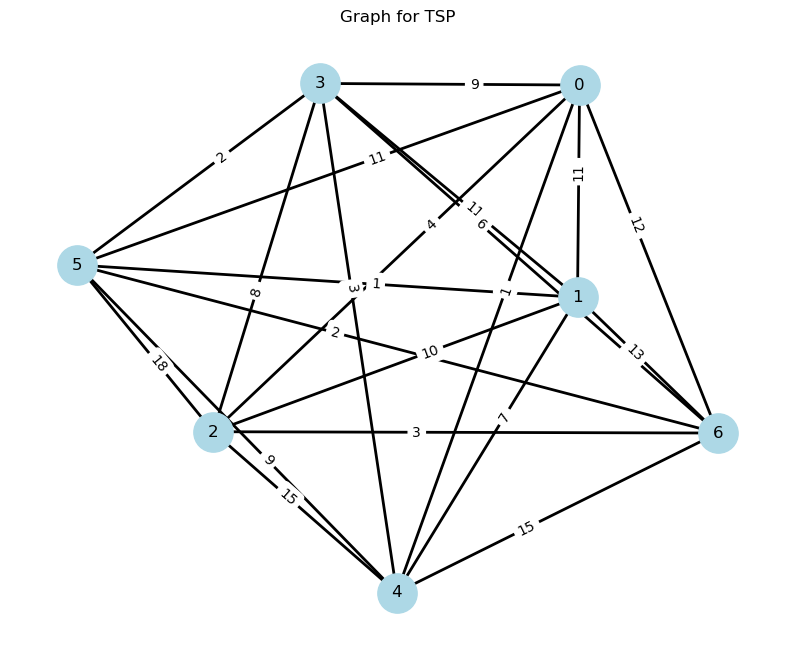

Nearest neighbor initialization:
[5, 1, 4, 0, 2, 6, 3]
[3, 5, 1, 4, 0, 2, 6, 3]
Shortest edge initialization:
[3, 4, 0, 2, 6, 5, 1]
[0, 2, 6, 5, 1, 3, 4, 0]
Partially matched crossover:
[[3, 4, 0, 2, 6, 5, 1], [3, 4, 0, 2, 6, 5, 1]]
([3, 4, 0, 2, 6, 5, 1], [3, 4, 0, 2, 6, 5, 1])
Order crossover:
[[3, 4, 0, 2, 6, 5, 1], [3, 4, 0, 2, 6, 5, 1]]
([3, 4, 0, 2, 6, 5, 1], [3, 4, 0, 2, 6, 5, 1])
Mutation by inversion:
[3, 4, 0, 2, 6, 5, 1] [3, 4, 0, 2, 6, 5, 1]
Mutation by insertion:
[3, 4, 0, 2, 6, 5, 1] [3, 4, 2, 0, 6, 5, 1]


In [2]:

import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from collections import defaultdict



def generate_random_weighted_graph(n, low, high):
    g = nx.complete_graph(n)

    g.add_weighted_edges_from(
        [(u, v, np.random.randint(low, high)) for u, v in g.edges()]
    )

    nx.set_node_attributes(g, nx.spring_layout(g, seed=42), "pos")
    return g



def plot_graph(g, title="", highlight_edges=None):
    if highlight_edges is None:
        highlight_edges = []

    pos = nx.get_node_attributes(g, "pos")

    plt.figure(figsize=(10, 8))
    plt.title(title)

    nx.draw(g, pos=pos, labels={x: x for x in g.nodes},
            node_color="lightblue", node_size=800, width=2)

    weights = nx.get_edge_attributes(g, "weight")

    nx.draw_networkx_edge_labels(
        g, pos, edge_labels=weights, label_pos=0.4
    )

    nx.draw_networkx_edges(
        g, pos, edgelist=highlight_edges,
        edge_color="r", width=3
    )

    plt.show()



def path_length(g, p):
    return sum(
        g[p[i]][p[i + 1]]["weight"]
        for i in range(len(p) - 1)
    )


def inv_path_length(g, p):
    distance = path_length(g, p)
    return 1 / distance if distance else 0



def roulette_wheel_selection(fitness_function, population):
    fitness = np.array([
        fitness_function(g, p) for p in population
    ], dtype=float)

    probabilities = fitness / fitness.sum()

    indices = np.random.choice(
        len(population),
        size=len(population),
        replace=True,
        p=probabilities
    )

    return [population[i].copy() for i in indices]



def nearest_neighbour_initialization(g, closed_tour=False):
    curr_node = int(np.random.choice(list(g.nodes)))
    path = [curr_node]

    not_visited = set(g.nodes) - {curr_node}

    while not_visited:
        curr_node = min(
            not_visited,
            key=lambda x: g[path[-1]][x]["weight"]
        )

        path.append(curr_node)
        not_visited.remove(curr_node)

    if closed_tour:
        path.append(path[0])

    return path


def get_path_from_edges(edges, closed_tour=False):
    path_graph = nx.Graph()
    path_graph.add_edges_from(edges)

    if closed_tour:
        start = min(path_graph.nodes)
    else:
        start = min(
            path_graph.nodes,
            key=path_graph.degree
        )

    path = [start]
    visited = {start}

    while len(path) < len(path_graph):
        current = path[-1]

        next_nodes = set(path_graph.neighbors(current)) - visited

        if not next_nodes:
            break

        next_node = next_nodes.pop()
        path.append(next_node)
        visited.add(next_node)

    if closed_tour:
        path.append(path[0])

    return path


def shortest_edge_initialization(g, closed_tour=False):
    edge_list = set(g.edges)
    times_visited = defaultdict(int)
    tour = set()

    max_tour_len = len(g) if closed_tour else len(g) - 1

    key = nx.get_edge_attributes(g, "weight").get

    while len(tour) < max_tour_len:
        u, v = min(edge_list, key=key)

        times_visited[u] += 1
        times_visited[v] += 1

        tour.add((u, v))
        edge_list.remove((u, v))

        for a, b in set(edge_list):
            temp = nx.Graph(tour | {(a, b)})

            if (
                (nx.is_forest(temp) is False
                 and len(tour) != len(g) - 1)
                or times_visited[a] == 2
                or times_visited[b] == 2
            ):
                edge_list.remove((a, b))

    return get_path_from_edges(tour, closed_tour)



def partially_matched_crossover(p1, p2):
    size = len(p1)

    pt = np.random.randint(1, size - 1)

    c1 = p1[:pt] + p2[pt:]
    c2 = p2[:pt] + p1[pt:]

    def make_valid_tour(p, nodes):
        unvisited = list(set(nodes) - set(p))
        indices = defaultdict(list)

        for i in range(len(p)):
            indices[p[i]].append(i)

        visited_twice = [
            node for node in indices if len(indices[node]) == 2
        ]

        for node in visited_twice:
            change_index = np.random.choice(indices[node])
            p[change_index] = unvisited.pop()

        return p

    nodes = set(p1)

    return make_valid_tour(c1, nodes), make_valid_tour(c2, nodes)



def order_crossover(p1, p2):
    start = np.random.randint(0, len(p1) - 1)
    end = np.random.randint(start + 1, len(p1))

    def fill_blanks(parent1, parent2, s, e):
        child = [None] * len(parent1)

        child[s:e] = parent1[s:e]

        remaining = [
            node for node in parent2 if node not in child
        ]

        positions = [
            i for i in range(len(child))
            if child[i] is None
        ]

        for i, node in zip(positions, remaining):
            child[i] = node

        return child

    c1 = fill_blanks(p1, p2, start, end)
    c2 = fill_blanks(p2, p1, start, end)

    return c1, c2



def inversion_mutation(p):
    start = np.random.randint(0, len(p) - 1)
    end = np.random.randint(start + 1, len(p) + 1)

    subtour = p[start:end]
    c = p.copy()

    for i in range(start, end):
        c[i] = subtour.pop()

    return c



def insertion_mutation(p):
    i = np.random.randint(1, len(p))
    k = np.random.randint(0, len(p) - 1)

    c = p.copy()
    c.insert(k, c.pop(i))

    return c




np.random.seed(3)

g = generate_random_weighted_graph(7, 1, 20)

print("Graph generation and display:")
plot_graph(g, "Graph for TSP")



print("Nearest neighbor initialization:")

np.random.seed(1)

print(nearest_neighbour_initialization(g))
print(nearest_neighbour_initialization(g, closed_tour=True))



print("Shortest edge initialization:")

np.random.seed(1)

print(shortest_edge_initialization(g))
print(shortest_edge_initialization(g, closed_tour=True))


print("Partially matched crossover:")

np.random.seed(2)

n_population = 8

population = [
    shortest_edge_initialization(g, closed_tour=False)
    for _ in range(n_population)
]

selected_population = roulette_wheel_selection(
    path_length, population
)

parents = selected_population[:2]

print(parents)
print(partially_matched_crossover(*parents))


print("Order crossover:")

np.random.seed(2)

population = [
    shortest_edge_initialization(g, closed_tour=False)
    for _ in range(n_population)
]

selected_population = roulette_wheel_selection(
    inv_path_length, population
)

parents = selected_population[:2]

print(parents)
print(order_crossover(*parents))


# Mutation by inversion
print("Mutation by inversion:")

np.random.seed(3)

population = [
    shortest_edge_initialization(g, closed_tour=False)
    for _ in range(n_population)
]

subject = population[0]

print(subject, inversion_mutation(subject))



print("Mutation by insertion:")

population = [
    shortest_edge_initialization(g, closed_tour=False)
    for _ in range(n_population)
]

subject = population[0]

print(subject, insertion_mutation(subject))
